# Практическая работа. Классическая, статистическая и геометрическая вероятность
По приложенному PDF «Практические занятия Листок 4». Внутри оригинала заголовок «Листок № 5»; сохранена исходная нумерация 4.1–4.17.

## Теория
**Вероятностная модель** — тройка $(\Omega,\mathcal F,P)$: пространство исходов, события и вероятностная мера. $P(\Omega)=1$, вероятности неотрицательны и счётно аддитивны.

**Классическая вероятность:** для равновозможных исходов $P(A)=|A|/|\Omega|$. Число сочетаний $C_n^k=n!/[k!(n-k)!]$. При выборке без возвращения используется гипергеометрическое распределение: $P(K=k)=C_M^kC_{N-M}^{m-k}/C_N^m$. С возвращением испытания независимы; количество успехов имеет биномиальное распределение $P(K=k)=C_m^kp^k(1-p)^{m-k}$.

**Статистическая вероятность:** $\widehat p_N=N_A/N$. Закон больших чисел объясняет приближение частоты к вероятности. Колебания не обязаны убывать монотонно. Типичная погрешность порядка $\sqrt{p(1-p)/N}$. Случайное зерно делает эксперимент воспроизводимым.

**Геометрическая вероятность:** при равномерном выборе $P(A)=\mu(A)/\mu(\Omega)$. Равномерность зависит от способа выбора: в круге радиус точки равен $R\sqrt U$, а не $RU$; последовательный выбор $X\sim U(0,1)$, $Y|X\sim U(0,X)$ даёт плотность $1/x$ на треугольнике.

**Условная вероятность:** $P(A|B)=P(A\cap B)/P(B)$. Формула полной вероятности: $P(A)=\sum_iP(H_i)P(A|H_i)$. Формула Байеса: $P(H_i|A)=P(H_i)P(A|H_i)/P(A)$.

**Монте-Карло:** генерируем независимые опыты, вычисляем индикаторы событий и накопленные частоты. Для условной вероятности считаем частоту только среди исходов условия. Все графики ниже строятся по реализованным опытам, а горизонтальные линии показывают аналитические значения.

## Задания и решения
Запуск: Python 3, библиотеки `numpy`, `matplotlib`, `scipy`, `sympy`. Выполните **Kernel → Restart & Run All**. Результаты и графики уже сохранены.

In [1]:
import math
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
import sympy as sp
from IPython.display import display
rng = np.random.default_rng(27)
N = 150_000
plt.rcParams.update({'figure.figsize': (9, 3.5), 'axes.grid': True})

def show(events, exact=None, title='Статистическая устойчивость'):
    exact = exact or {}
    fig, ax = plt.subplots()
    for name, event in events.items():
        event = np.asarray(event, dtype=bool)
        k = np.arange(1, len(event)+1)
        freq = np.cumsum(event)/k
        ix = np.unique(np.geomspace(1, len(k), 1100).astype(int))-1
        line, = ax.plot(k[ix], freq[ix], label=f'{name}: частота {freq[-1]:.6f}')
        if name in exact:
            p = float(exact[name])
            ax.axhline(p, color=line.get_color(), linestyle='--', alpha=.7)
            print(f'{name}: P = {exact[name]} ≈ {p:.9f}; частота = {freq[-1]:.9f}')
        else:
            print(f'{name}: частота = {freq[-1]:.9f}')
    ax.set(xlabel='Число опытов N', ylabel='Относительная частота', title=title)
    ax.legend(); plt.show()


## Задание 4.1

**Условие.** В корзине 8 белых, 6 синих и 9 красных шаров. Вынимают 6 шаров без возвращения. Найти вероятности: A — все красные; B — 3 синих, 2 белых, 1 красный; D — ровно 4 белых. Разобрать возвращение шаров и сопоставить с частотой 0,00358549.

**Решение.** Всего $C_{23}^6$ наборов. $P(A)=C_9^6/C_{23}^6=4/4807$; $P(B)=C_6^3C_8^2C_9^1/C_{23}^6$; $P(D)=C_8^4C_{15}^2/C_{23}^6$. С возвращением $P(A)=(9/23)^6$. Для B применяется мультиномиальная формула, для D — биномиальная. Частота 0,00358549 является оценкой, точное значение определяется моделью.

A: P = 4/4807 ≈ 0.000832120; частота = 0.000820000
B: P = 240/4807 ≈ 0.049927190; частота = 0.049874000
D: P = 350/4807 ≈ 0.072810485; частота = 0.073002000
A: P = 531441/148035889 ≈ 0.003589947; частота = 0.003604000
B: P = 7464960/148035889 ≈ 0.050426691; частота = 0.050530000
D: P = 13824000/148035889 ≈ 0.093382761; частота = 0.093710000


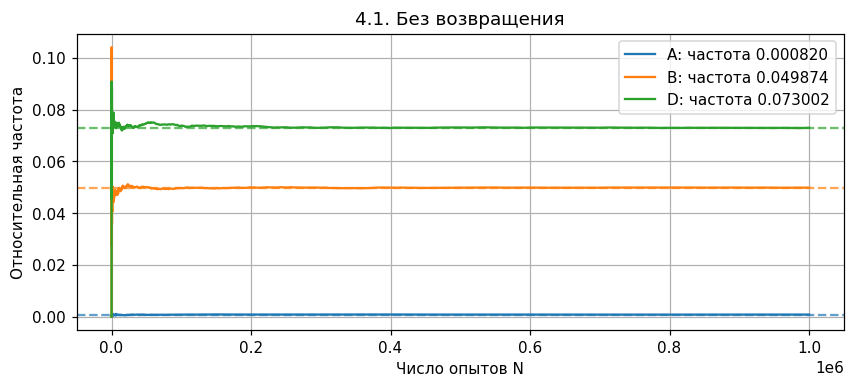

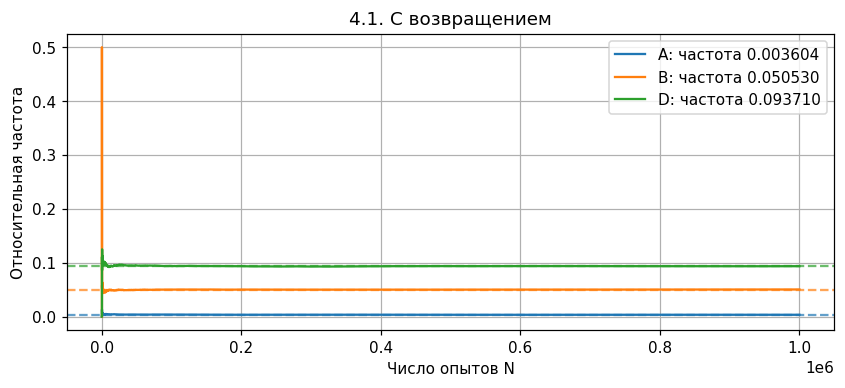

In [2]:
den = math.comb(23,6)
p1 = {'A':Fraction(math.comb(9,6),den), 'B':Fraction(math.comb(6,3)*math.comb(8,2)*9,den), 'D':Fraction(math.comb(8,4)*math.comb(15,2),den)}
v = rng.multivariate_hypergeometric([8,6,9],6,size=1_000_000)
show({'A':v[:,2]==6,'B':np.all(v==[2,3,1],axis=1),'D':v[:,0]==4},p1,'4.1. Без возвращения')
v = rng.multinomial(6,np.array([8,6,9])/23,size=1_000_000)
p2={'A':Fraction(9,23)**6,'B':60*Fraction(6,23)**3*Fraction(8,23)**2*Fraction(9,23),'D':15*Fraction(8,23)**4*Fraction(15,23)**2}
show({'A':v[:,2]==6,'B':np.all(v==[2,3,1],axis=1),'D':v[:,0]==4},p2,'4.1. С возвращением')

## Задание 4.2

**Условие.** 5 мужчин и 5 женщин рассаживаются в ряд. A — женщины не соседствуют; B — мужчины сидят рядом.

**Решение.** Из $C_{10}^5=252$ половых последовательностей для A подходят $C_6^5=6$: женщины занимают пять из шести промежутков между мужчинами. Для B шесть вариантов положения блока мужчин. Поэтому обе вероятности равны $6/252=1/42$. Перестановки конкретных людей сокращаются.

A: P = 1/42 ≈ 0.023809524; частота = 0.024313333
B: P = 1/42 ≈ 0.023809524; частота = 0.024006667


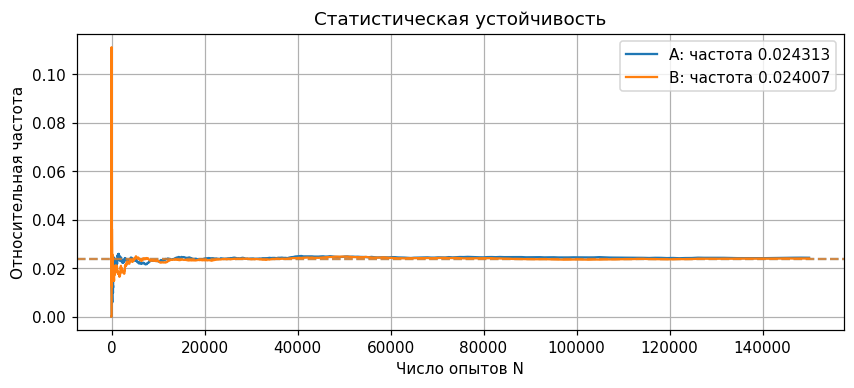

In [3]:
v=np.argsort(rng.random((N,10)),axis=1)<5
show({'A':~np.any(v[:,:-1]&v[:,1:],axis=1),'B':np.ptp(np.sort(np.where(~v,np.arange(10),99),axis=1)[:,:5],axis=1)==4},{'A':Fraction(1,42),'B':Fraction(1,42)})

## Задание 4.3

**Условие.** Симметричную монету бросают до первого герба. Найти вероятность не более пяти бросаний.

**Решение.** $\Omega=\{Р^{k-1}Г:k\ge1\}$, $P(T=k)=2^{-k}$. Дополнительное событие — первые пять бросков решки. $P(T\le5)=1-2^{-5}=31/32$.

T ≤ 5: P = 31/32 ≈ 0.968750000; частота = 0.968873333


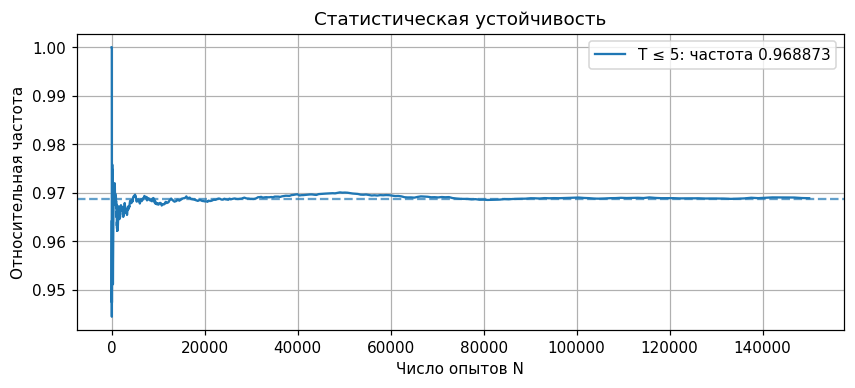

In [4]:
t=rng.geometric(.5,N)
show({'T ≤ 5':t<=5},{'T ≤ 5':Fraction(31,32)})

In [5]:
def coin_times(p, size):
    previous=rng.random(size)<p
    active=np.arange(size)
    times=np.zeros(size,dtype=int)
    t=1
    while active.size:
        t+=1
        current=rng.random(active.size)<p
        done=current==previous[active]
        times[active[done]]=t
        previous[active]=current
        active=active[~done]
    return times

## Задание 4.4

**Условие.** Честную монету бросают до первого совпадения двух соседних сторон. Построить модель и найти вероятность чётного числа бросаний.

**Решение.** Исходы — конечные чередующиеся последовательности, завершённые первым повтором; вероятность строки с $h$ гербами и $t$ решками равна $p^h(1-p)^t$. Вероятность бесконечного чередования равна нулю. При $r=p(1-p)$: $P(T=2k)=r^{k-1}(p^2+(1-p)^2)=r^{k-1}(1-2r)$, $P(T=2k+1)=r^k$. Поэтому $P(T\text{ чётно})=(1-2r)/(1-r)$ и $P(T\equiv0\pmod4)=(1-2r)r/(1-r^2)$. При $p=1/2$ ответ $2/3$.

Чётное T: P = 2/3 ≈ 0.666666667; частота = 0.665186667


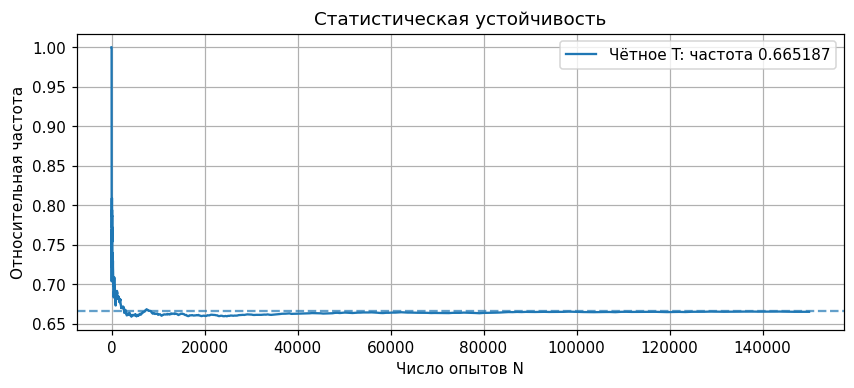

In [6]:
t=coin_times(.5,N)
show({'Чётное T':t%2==0},{'Чётное T':Fraction(2,3)})

## Задание 4.5

**Условие.** Та же остановка, но P(герб)=0,7. Найти вероятность чётного T и T, кратного 4.

**Решение.** Исходы — конечные чередующиеся последовательности, завершённые первым повтором; вероятность строки с $h$ гербами и $t$ решками равна $p^h(1-p)^t$. Вероятность бесконечного чередования равна нулю. При $r=p(1-p)$: $P(T=2k)=r^{k-1}(p^2+(1-p)^2)=r^{k-1}(1-2r)$, $P(T=2k+1)=r^k$. Поэтому $P(T\text{ чётно})=(1-2r)/(1-r)$ и $P(T\equiv0\pmod4)=(1-2r)r/(1-r^2)$. Подставляем $r=21/100$.

Чётное T: P = 58/79 ≈ 0.734177215; частота = 0.735320000
T кратно 4: P = 1218/9559 ≈ 0.127419186; частота = 0.127313333


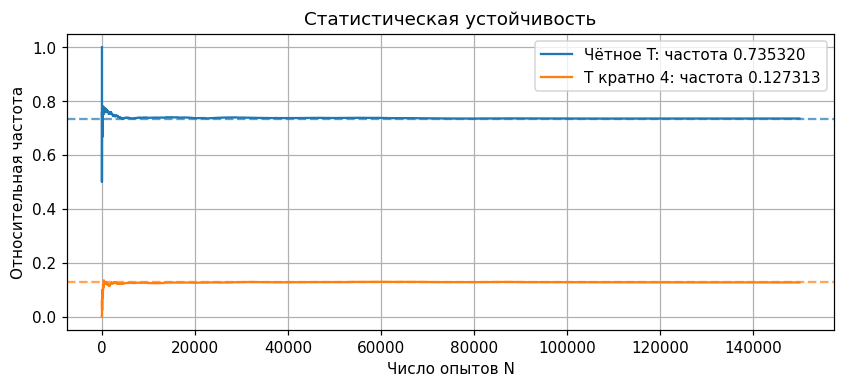

In [7]:
t=coin_times(.7,N)
r=Fraction(21,100)
show({'Чётное T':t%2==0,'T кратно 4':t%4==0},{'Чётное T':(1-2*r)/(1-r),'T кратно 4':(1-2*r)*r/(1-r*r)})

## Задание 4.6

**Условие.** Встреча между 14 и 15 часами: A ждёт 10 минут, B — 12. Найти вероятность встречи; 150000 опытов.

**Решение.** Пусть $x,y$ — минуты прихода A и B. Встреча при $y\le x+10$ и $x\le y+12$. В квадрате площади 3600 исключаем треугольники площадей $50^2/2$ и $48^2/2$. Ответ $1-(50^2+48^2)/7200=599/1800$.

Встреча: P = 599/1800 ≈ 0.332777778; частота = 0.333566667


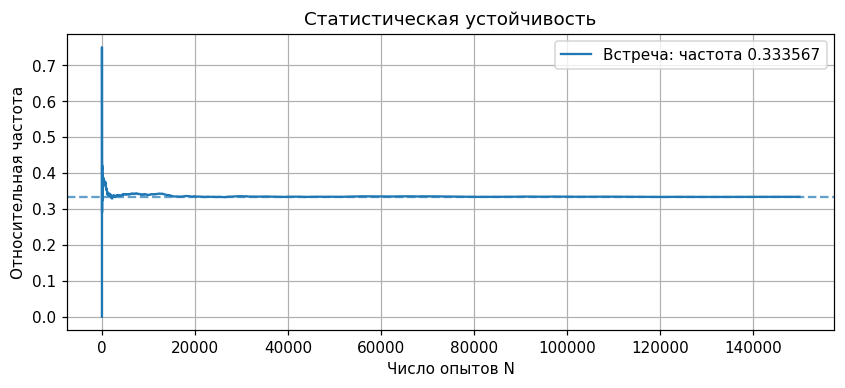

In [8]:
x,y=rng.uniform(0,60,(2,N))
show({'Встреча':(y<=x+10)&(x<=y+12)},{'Встреча':Fraction(599,1800)})

## Задание 4.7

**Условие.** Иван и Пётр приходят между 11 и 12, ждут не более 15 минут и до конца часа. Найти A — встреча; B — нет; C — Ивану не пришлось ждать; D — встреча после 11:30; E — Иван опоздал; F — встреча в последние 5 минут. 150000 опытов.

**Решение.** Нормируем время к [0,1]. A: $|x-y|\le1/4$, B — дополнение. C понимаем как состоявшуюся встречу с Петром, который уже пришёл: $y\le x\le y+1/4$. E — Иван пришёл позже Петра ($x>y$), независимо от встречи. Без назначенного точного времени иного определения опоздания нет. D: A и $\max(x,y)>1/2$; F: A и $\max(x,y)>11/12$. Получаем $P(A)=7/16$, $P(B)=9/16$, $P(C)=7/32$, $P(D)=1/4$, $P(E)=1/2$, $P(F)=1/24$. Если C трактовать просто как «пришёл не раньше Петра», его вероятность 1/2; если E требует встречи, ответ 7/32.

A: P = 7/16 ≈ 0.437500000; частота = 0.438520000
B: P = 9/16 ≈ 0.562500000; частота = 0.561480000
C: P = 7/32 ≈ 0.218750000; частота = 0.218640000
D: P = 1/4 ≈ 0.250000000; частота = 0.252286667
E: P = 1/2 ≈ 0.500000000; частота = 0.500526667
F: P = 1/24 ≈ 0.041666667; частота = 0.042326667


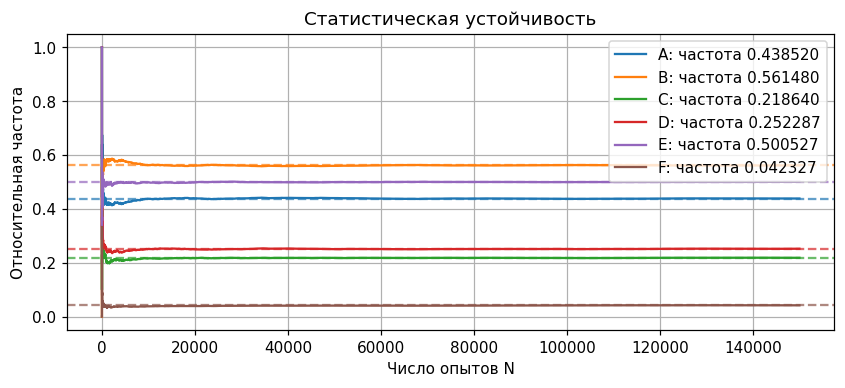

In [9]:
x,y=rng.random((2,N)); a=abs(x-y)<=.25
show({'A':a,'B':~a,'C':a&(x>=y),'D':a&(np.maximum(x,y)>.5),'E':x>y,'F':a&(np.maximum(x,y)>11/12)},dict(zip('ABCDEF',map(Fraction,['7/16','9/16','7/32','1/4','1/2','1/24']))))

## Задание 4.8

**Условие.** На [a,b] выбирается X, затем на [a,X] — Y. A: Y ближе к b, чем X к a; B: расстояние XY меньше половины отрезка; C: X ближе к Y, чем к b. 150000 опытов.

**Решение.** После нормировки $0\le y\le x\le1$, плотность $f(x,y)=1/x$. A: $1-y<x$, поэтому $P(A)=\int_{1/2}^1(2x-1)/x\,dx=1-\ln2$. B: $x-y<1/2$, откуда $P(B)=1/2+\int_{1/2}^1(1/2)/x\,dx=(1+\ln2)/2$. C: $x-y<1-x$, откуда $P(C)=1/2+\int_{1/2}^1(1-x)/x\,dx=\ln2$.

A: P = 0.3068528194400547 ≈ 0.306852819; частота = 0.305886667
B: P = 0.8465735902799727 ≈ 0.846573590; частота = 0.846866667
C: P = 0.6931471805599453 ≈ 0.693147181; частота = 0.693546667


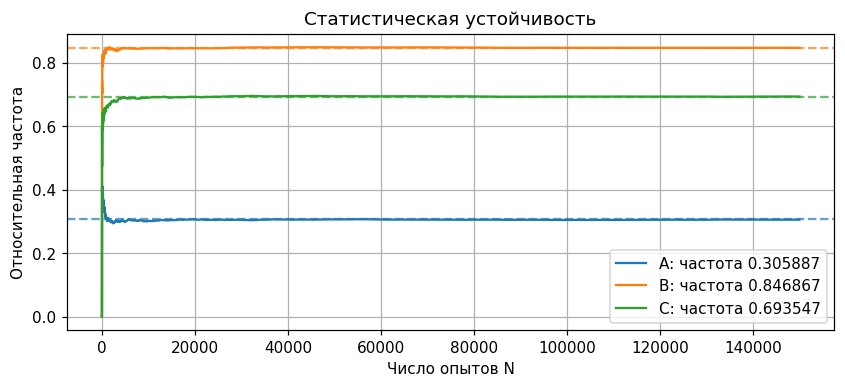

In [10]:
x=rng.random(N); y=x*rng.random(N)
show({'A':1-y<x,'B':x-y<.5,'C':x-y<1-x},{'A':1-np.log(2),'B':(1+np.log(2))/2,'C':np.log(2)})

## Задание 4.9

**Условие.** Отрезок [0,1] разделяют двумя независимыми равномерными точками. Найти вероятность образования остроугольного треугольника аналитически и в 150000 опытах.

**Решение.** Обозначим длины $a,b,c$, $a+b+c=1$. Условие: квадрат наибольшей стороны меньше суммы квадратов двух других. Площадь симплекса $(a,b)$ равна 1/2. По симметрии выбираем наибольшую сторону $c$, кладём $a=(1-c+d)/2$, $b=(1-c-d)/2$, якобиан 1/2. При $1/3\le c\le\sqrt2-1$ разрешено $|d|\le3c-1$; при $\sqrt2-1<c<1/2$ дополнительно $|d|>\sqrt{c^2+2c-1}$. Поэтому
$$P=6\left[\int_{1/3}^{1/2}(3c-1)dc-\int_{\sqrt2-1}^{1/2}\sqrt{c^2+2c-1}\,dc\right]=3\ln2-2.$$
Равенства на границе имеют нулевую вероятность.

Остроугольный: P = 0.07944154167983575 ≈ 0.079441542; частота = 0.079366667


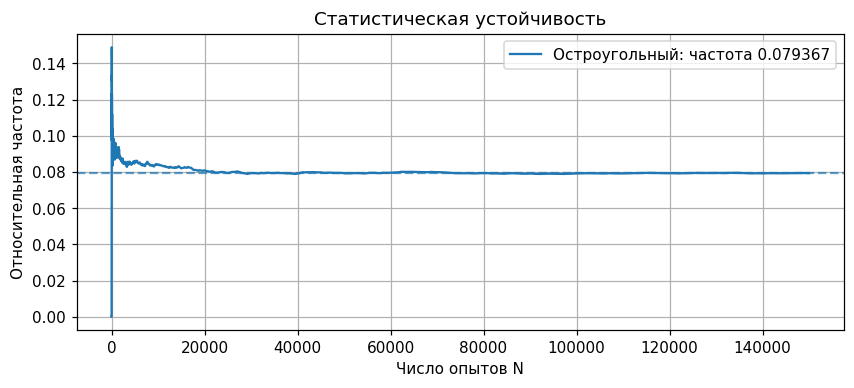

In [11]:
cuts=np.sort(rng.random((N,2)),axis=1)
s=np.column_stack([cuts[:,0],cuts[:,1]-cuts[:,0],1-cuts[:,1]])
a=2*np.max(s*s,axis=1)<np.sum(s*s,axis=1)
show({'Остроугольный':a},{'Остроугольный':3*np.log(2)-2})

## Задание 4.10

**Условие.** В единичном круге наудачу выбирается отрезок. Найти вероятность длины меньше радиуса.

**Решение.** Для однозначности принимаем модель двух независимых равномерных точек внутри диска: именно она соответствует ответу PDF. Случайная хорда была бы другой моделью. Плотность расстояния $d\in[0,2]$ равна $\frac{4d}{\pi}[\arccos(d/2)-(d/2)\sqrt{1-d^2/4}]$. Интегрируя от 0 до 1, получаем $1-3\sqrt3/(4\pi)$.

Длина < 1: P = 0.5865033284336559 ≈ 0.586503328; частота = 0.585913333


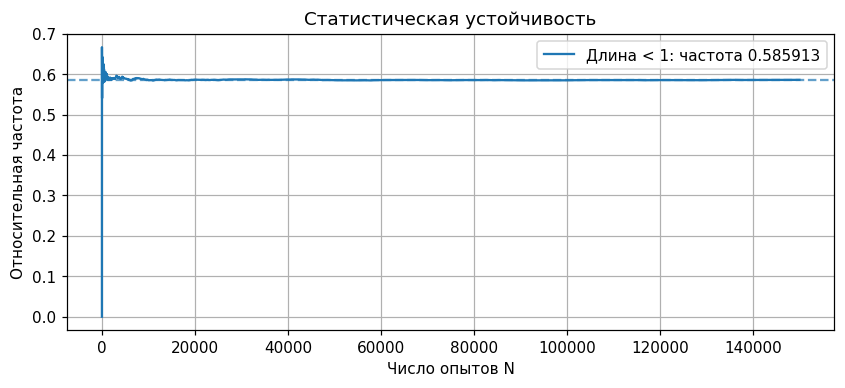

In [12]:
def disk(size, ax=1, by=1):
    r=np.sqrt(rng.random(size)); t=rng.uniform(0,2*np.pi,size)
    return np.column_stack([ax*r*np.cos(t),by*r*np.sin(t)])
a=disk(N); b=disk(N)
show({'Длина < 1':np.linalg.norm(a-b,axis=1)<1},{'Длина < 1':1-3*np.sqrt(3)/(4*np.pi)})

## Задание 4.11

**Условие.** n человек приходят равномерно за час и ждут 60q минут. Доказать Pn=nq^(n−1)−(n−1)q^n; проверить n=2,3. При n=3 найти вероятность встречи хотя бы двух.

**Решение.** Встреча всех эквивалентна $\max X_i-\min X_i\le q$. Выбираем самого раннего (n способов), время его прихода t. Остальные должны попасть в интервал длины $\min(q,1-t)$. Тогда $P_n=n\int_0^1\min(q,1-t)^{n-1}dt=n(1-q)q^{n-1}+q^n$. При n=2: $2q-q^2$; n=3: $3q^2-2q^3$. Для трёх отсутствие любой встречи означает оба промежутка между упорядоченными приходами больше q. Сдвиг координат даёт вероятность $(1-2q)^3$ при $q\le1/2$, иначе 0. Ответ для хотя бы двух: $1-\max(1-2q,0)^3$. Численная проверка при q=1/4.

Все 2: P = 0.4375 ≈ 0.437500000; частота = 0.435340000
Все 3: P = 0.15625 ≈ 0.156250000; частота = 0.158440000
Хотя бы двое: P = 0.875 ≈ 0.875000000; частота = 0.875766667


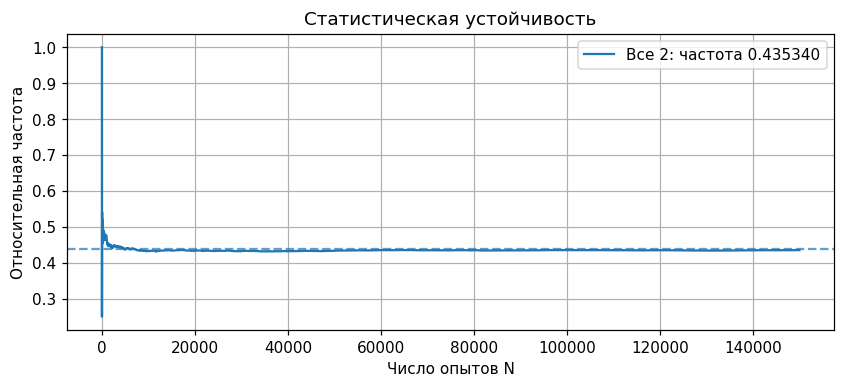

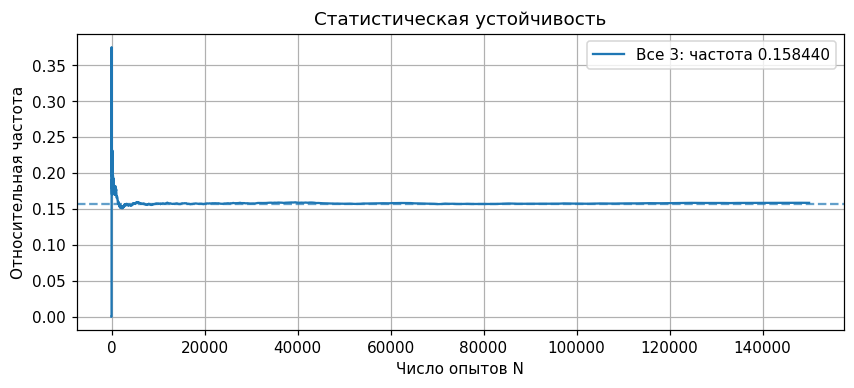

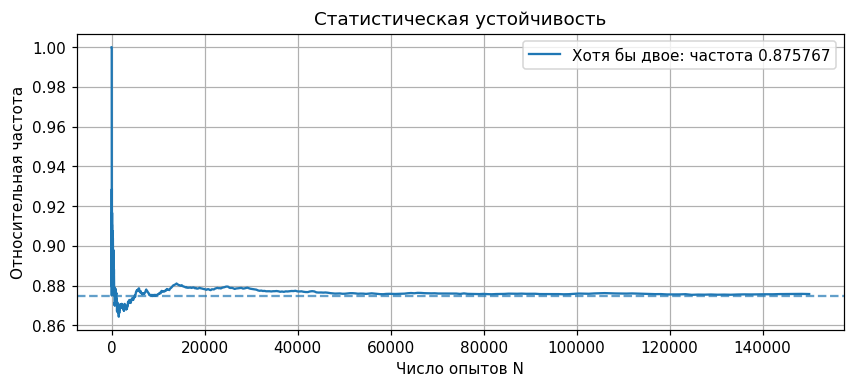

In [13]:
q=.25
for count in (2,3):
    x=rng.random((N,count))
    show({f'Все {count}':np.ptp(x,axis=1)<=q},{f'Все {count}':count*q**(count-1)-(count-1)*q**count})
    if count==3:
        show({'Хотя бы двое':np.min(np.diff(np.sort(x,axis=1)),axis=1)<=q},{'Хотя бы двое':1-max(1-2*q,0)**3})

## Задание 4.12

**Условие.** Разные времена ожидания w1,…,wn: доказать формулы для n=2,3,4; вычислить n=3 при 1/4,1/3,1/2.

**Решение.** Положим $0\le w_i\le1$. Если последний пришедший — j в момент t, каждому другому нужно прийти в $[\max(0,t-w_i),t]$. Поэтому
$$P_n=\sum_{j=1}^n\int_0^1\prod_{i\ne j}\min(t,w_i)\,dt.$$
Это доказательство общей формулы: случаи последнего пришедшего несовместны с точностью до множества меры нуль. Для полиномиальных формул PDF обязательно предварительно упорядочить $w_1\le\dots\le w_n$; иначе они несимметричны и неверны. Интеграл разбиваем по точкам $w_i$ и интегрируем многочлены. Код ниже выводит и проверяет формулы для n=2,3,4. Для n=3 результат $1435/5184\approx0{,}276813$.

n=2, при w1 ≤ ... ≤ w2:
-w1**2/2 + w1 - w2**2/2 + w2
n=2: P = 19/32 ≈ 0.593750000; частота = 0.592866667
n=3, при w1 ≤ ... ≤ w3:
-w1**3/3 - w1*w2**2/2 + w1*w2 - w1*w3**2/2 + w1*w3 - w2**3/6 - w2*w3**2/2 + w2*w3
n=3: P = 1435/5184 ≈ 0.276813272; частота = 0.274546667
n=4, при w1 ≤ ... ≤ w4:
-w1**4/4 - w1*w2**3/3 - w1*w2*w3**2/2 + w1*w2*w3 - w1*w2*w4**2/2 + w1*w2*w4 - w1*w3**3/6 - w1*w3*w4**2/2 + w1*w3*w4 - w2**4/12 - w2*w3**3/6 - w2*w3*w4**2/2 + w2*w3*w4
n=4: P = 247/1728 ≈ 0.142939815; частота = 0.141933333


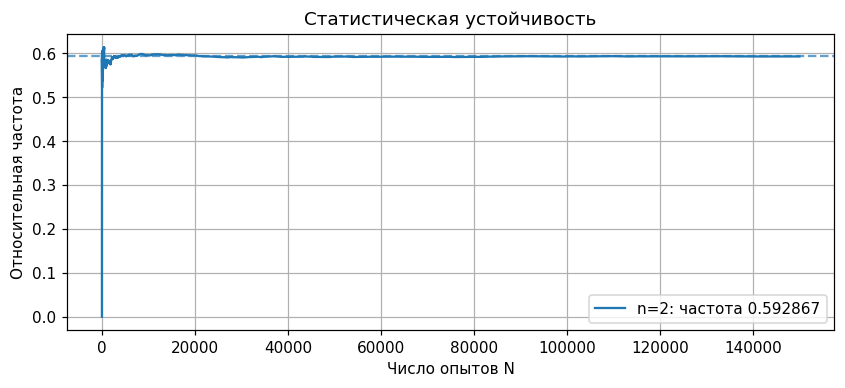

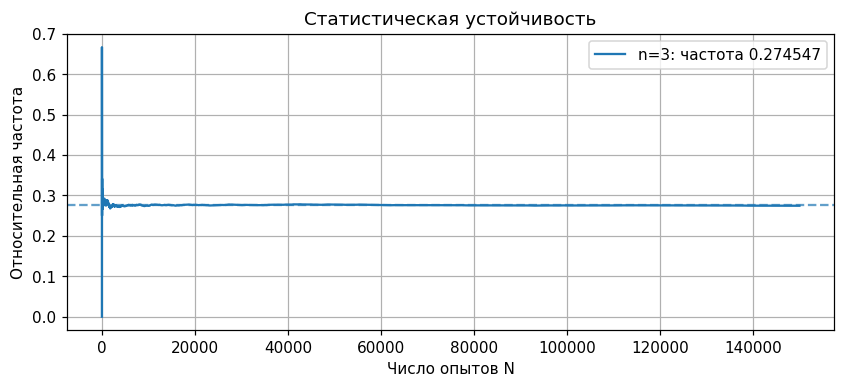

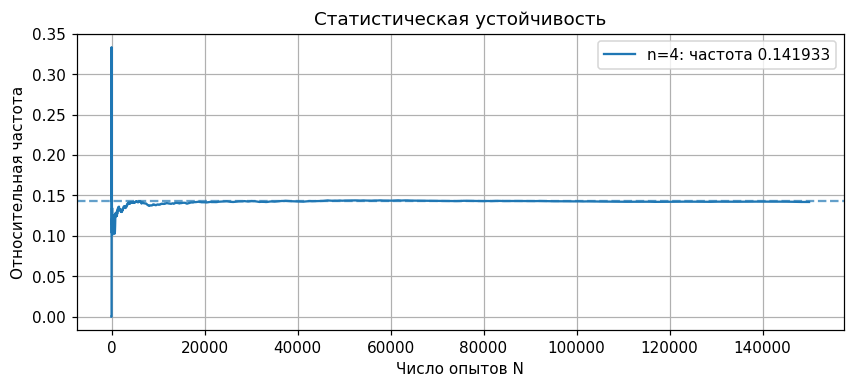

In [14]:
t=sp.symbols('t', real=True)
def symbolic_meeting(count):
    w=sp.symbols('w1:'+str(count+1), positive=True)
    bounds=[sp.Integer(0),*w,sp.Integer(1)]
    result=0
    for j in range(count):
        for k in range(count+1):
            prod=sp.prod(w[i] if i<k else t for i in range(count) if i!=j)
            result+=sp.integrate(prod,(t,bounds[k],bounds[k+1]))
    return w,sp.expand(result)
for count in (2,3,4):
    w,formula=symbolic_meeting(count)
    print(f'n={count}, при w1 ≤ ... ≤ w{count}:'); display(formula)
    vals=([sp.Rational(1,4),sp.Rational(1,3),sp.Rational(1,2)] if count==3
          else [sp.Rational(i+1,count+2) for i in range(count)])
    p=formula.subs(dict(zip(w,vals)))
    arrivals=rng.random((N,count)); last=arrivals.max(axis=1)
    event=np.all(last[:,None]-arrivals<=np.array(vals,dtype=float),axis=1)
    show({f'n={count}':event},{f'n={count}':p})
    if count==3: assert p==sp.Rational(1435,5184)


## Задание 4.13

**Условие.** В корзину с n шарами добавили белый. Изначально число белых K~Bin(n,p). Найти вероятность белого шара; n=10,p=1/3.

**Решение.** При данном K вероятность равна $(K+1)/(n+1)$. Усредняем: $P=(E[K]+1)/(n+1)=(np+1)/(n+1)$. Для n=10,p=1/3 получаем $13/33\approx0{,}393939$. Указанное в PDF значение 0,15625 не соответствует условию.

Белый: P = 13/33 ≈ 0.393939394; частота = 0.394873333


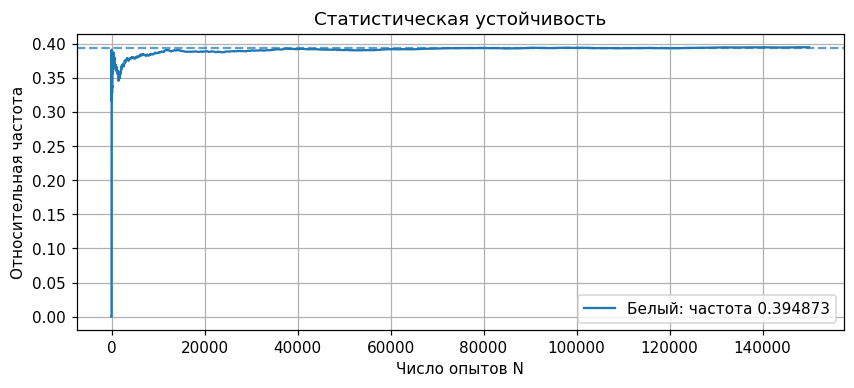

In [15]:
k=rng.binomial(10,1/3,N)
show({'Белый':rng.random(N)<(k+1)/11},{'Белый':Fraction(13,33)})

## Задание 4.14

**Условие.** Корзина 1: всего 6 шаров, белых Bin(3,0.8). Корзина 2: всего 11, белых Bin(4,0.7). Всё объединяют. Найти P(белый) и P(из 1|белый).

**Решение.** Ожидаемые количества белых равны 2,4 и 2,8. $P(A)=(2{,}4+2{,}8)/17=26/85$. $P(H\cap A)=2{,}4/17$, поэтому $P(H|A)=2{,}4/5{,}2=6/13$.

Белый: P = 26/85 ≈ 0.305882353; частота = 0.304280000
Из первой | белый: P = 6/13 ≈ 0.461538462; частота = 0.458064940


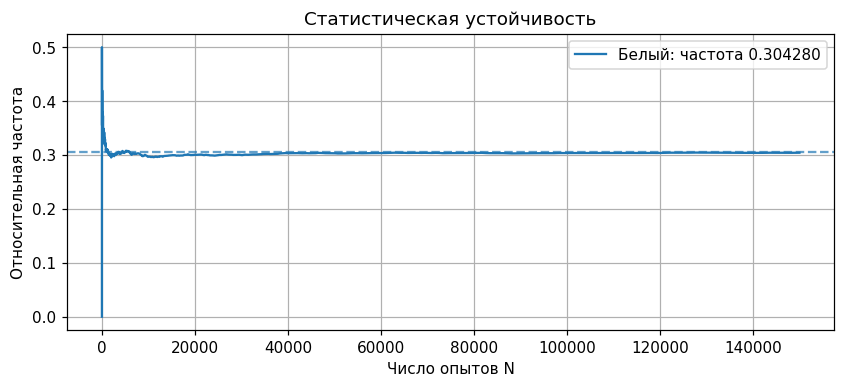

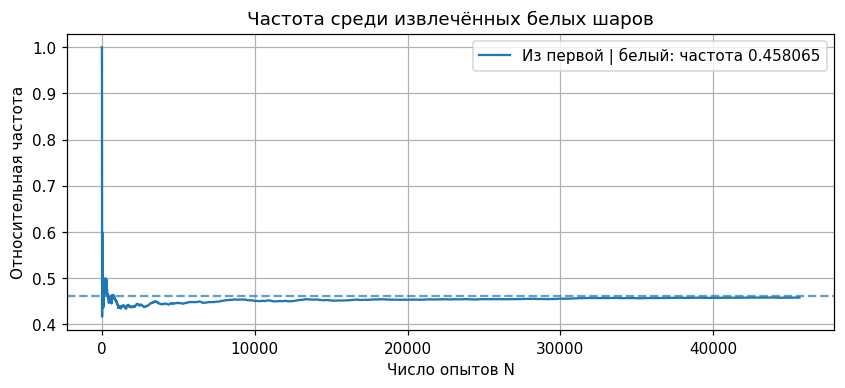

In [16]:
k1=rng.binomial(3,.8,N); k2=rng.binomial(4,.7,N)
u=rng.integers(0,17,N)
a=(u<k1)|((u>=6)&(u<6+k2))
show({'Белый':a},{'Белый':Fraction(26,85)})
show({'Из первой | белый':(u<6)[a]},{'Из первой | белый':Fraction(6,13)},'Частота среди извлечённых белых шаров')

## Задание 4.15

**Условие.** В прямоугольнике |x|≤20, |y|≤8 выбирают две точки. A: расстояние <11; B: |x1−x2|<14. По 100000 парам оценить P(A), P(A|B).

**Решение.** Генерируем координаты независимо и равномерно. $\widehat P(A)=N_A/N$, $\widehat P(A|B)=N_{A\cap B}/N_B$. Здесь A влечёт B, но для наглядности используем общую формулу. В PDF требование одного знака после запятой расходится с ответами из двух знаков; выведены оба округления.

A: частота = 0.369270000
A | B: частота = 0.640193478
P(A): 0.369270; до 1 знака: 0.4; до 2 знаков: 0.37
P(A|B): 0.640193; до 1 знака: 0.6; до 2 знаков: 0.64


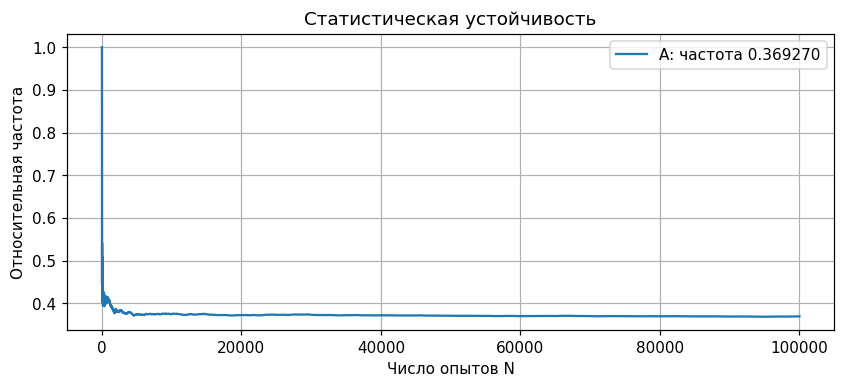

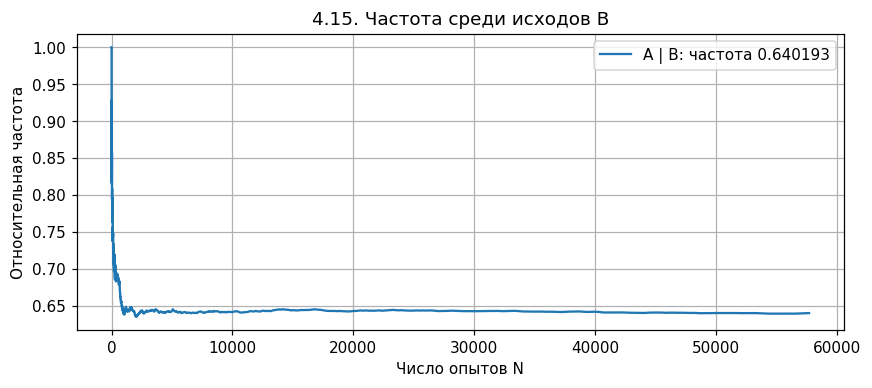

In [17]:
x=rng.uniform(-20,20,(100_000,2)); y=rng.uniform(-8,8,(100_000,2))
dx=x[:,0]-x[:,1]; dy=y[:,0]-y[:,1]
a=dx*dx+dy*dy<121; b=abs(dx)<14
show({'A':a}); show({'A | B':a[b]},title='4.15. Частота среди исходов B')
for name,p in [('P(A)',a.mean()),('P(A|B)',a[b].mean())]:
    print(f'{name}: {p:.6f}; до 1 знака: {p:.1f}; до 2 знаков: {p:.2f}')

## Задание 4.16

**Условие.** В эллипсе (u/23)²+(v/6)²≤1 выбирают две точки. A: расстояние <9,2; B: первая точка в первом квадранте, вторая — в третьем. 100000 пар, P(A),P(A|B).

**Решение.** Равномерные точки диска преобразуем линейно: $(u,v)=(23\sqrt U\cos\theta,6\sqrt U\sin\theta)$. Постоянный якобиан сохраняет равномерность в эллипсе. Условие B проверяем по всем четырём координатам. Ответы округляем до одного и двух знаков.

A: частота = 0.350360000
A | B: частота = 0.068771139
Число пар с B: 6209
P(A): 0.350360; до 1 знака: 0.4; до 2 знаков: 0.35
P(A|B): 0.068771; до 1 знака: 0.1; до 2 знаков: 0.07


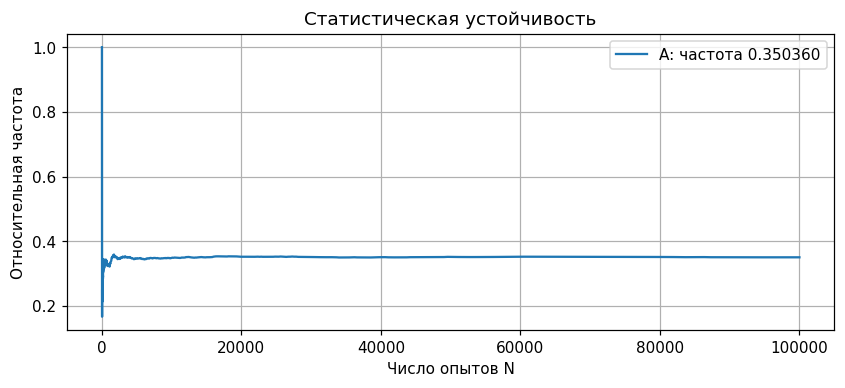

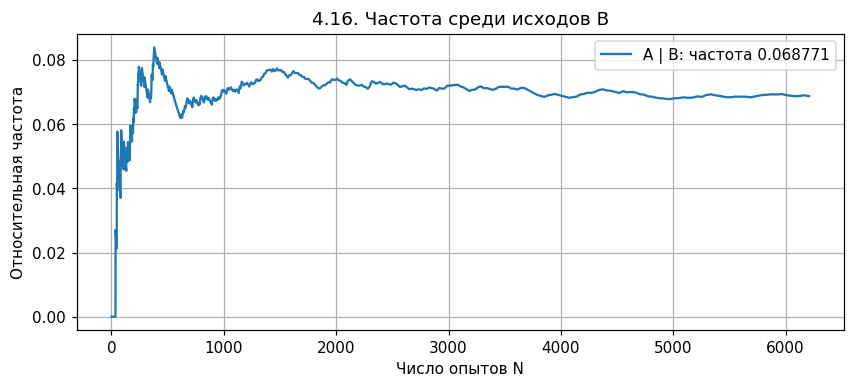

In [18]:
p1=disk(100_000,23,6); p2=disk(100_000,23,6)
a=np.linalg.norm(p1-p2,axis=1)<9.2
b=np.all(p1>0,axis=1)&np.all(p2<0,axis=1)
show({'A':a}); show({'A | B':a[b]},title='4.16. Частота среди исходов B')
print('Число пар с B:',b.sum())
for name,p in [('P(A)',a.mean()),('P(A|B)',a[b].mean())]:
    print(f'{name}: {p:.6f}; до 1 знака: {p:.1f}; до 2 знаков: {p:.2f}')

## Задание 4.17

**Условие.** В единичном кубе выбирают A,B,C. R: минимальный угол <26,7°; S: максимальный <81,9°; T: треугольник остроугольный. Получить 100000 остроугольных треугольников и оценить P(R|T),P(S|T).

**Решение.** Углы вычисляем скалярными произведениями векторов с общей вершиной. Принимаем только треугольники, у которых все косинусы положительны. Набираем именно 100000 принятых треугольников, а не 100000 исходных троек. На принятой выборке считаем частоты R и S.

Сгенерировано троек: 300000 ; использовано остроугольных: 100000
R | T: частота = 0.111190000
S | T: частота = 0.654850000
P(R|T): 0.111190; до 1 знака: 0.1; до 2 знаков: 0.11
P(S|T): 0.654850; до 1 знака: 0.7; до 2 знаков: 0.65


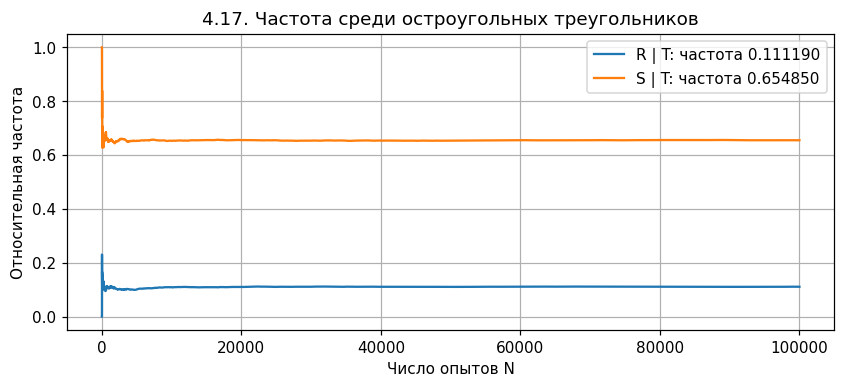

In [19]:
accepted=[]; collected=0; generated=0
while collected<100_000:
    pts=rng.random((100_000,3,3)); generated+=len(pts)
    angles=[]
    for j in range(3):
        u=pts[:,(j+1)%3]-pts[:,j]; v=pts[:,(j+2)%3]-pts[:,j]
        cos=np.sum(u*v,axis=1)/(np.linalg.norm(u,axis=1)*np.linalg.norm(v,axis=1))
        angles.append(np.degrees(np.arccos(np.clip(cos,-1,1))))
    angles=np.column_stack(angles)
    acute=angles[np.max(angles,axis=1)<90]
    accepted.append(acute); collected+=len(acute)
angles=np.concatenate(accepted)[:100_000]
r=angles.min(axis=1)<26.7; s=angles.max(axis=1)<81.9
print('Сгенерировано троек:',generated,'; использовано остроугольных:',len(angles))
show({'R | T':r,'S | T':s},title='4.17. Частота среди остроугольных треугольников')
for name,p in [('P(R|T)',r.mean()),('P(S|T)',s.mean())]:
    print(f'{name}: {p:.6f}; до 1 знака: {p:.1f}; до 2 знаков: {p:.2f}')

## Вывод
Решены задачи 4.1–4.17. Комбинаторные и геометрические формулы сопоставлены с моделированием; для условных вероятностей построены частоты по выборке, удовлетворяющей условию. Редкие события требуют большего числа опытов, что видно в 4.1. В задачах с неоднозначной формулировкой указана выбранная модель. Исправлен ответ 4.13 и уточнено необходимое упорядочение времён ожидания в полиномиальных формулах 4.12.